## Latar Belakang

Batik Lestari adalah UMKM batik asal Pekalongan (fiktif) yang menjual kemeja, dress, kain batik, outer, dan
aksesoris. Penjualannya berjalan di empat channel: Shopee, Tokopedia, TikTok Shop, dan toko offline di
Pekalongan.

Kuartal 4 adalah musim terpenting bagi bisnis batik. Ada Hari Batik Nasional (2 Oktober), kampanye tanggal
kembar marketplace (10.10, 11.11, dan 12.12), serta musim belanja akhir tahun. **Pemilik usaha, Bu Ratna, ingin
menentukan prioritas: channel mana yang harus digenjot, produk mana yang harus disiapkan stoknya, dan
masalah apa yang harus dibereskan**.

Masalahnya, data penjualan Juli sampai September 2026 dicatat dari beberapa channel oleh beberapa admin
yang berbeda. Hasilnya: *ada data dobel, penulisan yang tidak seragam, dan data yang kosong*. Bu Ratna butuh
tim analis untuk merapikan data ini lalu menerjemahkannya menjadi keputusan bisnis.

## Import Library

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Load Dataset

In [ ]:
# Sumber dataset
url = "https://docs.google.com/spreadsheets/d/1Mni56DBsqLTu5Q88KZan_M6czmKQtl-9MywMx_CtDQI/export?format=csv"

In [ ]:
# Load dataset
raw_df = pd.read_csv(url)

raw_df.head()

,id_pesanan,tanggal_pesanan,channel,kota_pembeli,kategori,produk,harga_satuan,jumlah,diskon_persen,metode_bayar,status_pesanan,rating
0,BL-00001,2026-07-01,Shopee,Yogyakarta,Kemeja Pria,Kemeja Batik Parang Lengan Pendek,185000,1,5,Transfer Bank,Selesai,5.0
1,BL-00002,2026-07-01,Tokopedia,Pekalongan,Aksesoris,Scarf Batik Sutra,95000,1,10,COD,Selesai,4.0
2,BL-00003,2026-07-01,Toko Offline,Pekalongan,Kemeja Pria,Kemeja Batik Kawung Slim Fit,215000,1,10,QRIS,Selesai,5.0
3,BL-00004,2026-07-01,Toko Offline,Semarang,Kemeja Pria,Kemeja Batik Mega Mendung Lengan Panjang,245000,3,0,QRIS,Selesai,4.0
4,BL-00005,2026-07-01,Toko Offline,Jakarta,Outer,Outer Batik Kimono,159000,2,5,Kartu Debit,Selesai,4.0


## Kenalan dengan Data

### Deskripsi Dataset

| Kolom | Deskripsi |
|-------|-----------|
| id_pesanan | nomor unik yang digunakan sebagai identitas pesanan/transaksi |
| tanggal_pesanan | tanggal pesanan dibuat |
| channel | platform penjualan |
| kota_pembeli | kota tujuan pengiriman atau kota asal pembeli |
| kategori | kelompok produk |
| produk | nama produk |
| harga_satuan | harga per item sebelum diskon (Rp) |
| jumlah | kuantitas item dalam pesanan |
| diskon_persen | persentase diskon yang berlaku pada setiap pesanan |
| metode_bayar | cara pembayaran yang dipilih oleh pembeli |
| status_pesanan | status akhir pesanan |
| rating | penilaian ulasan yang diberikan oleh pembeli (nilai 1 sampai 5) |

### Kondisi Data Mentah


| Assessment | Catatan |
|------------|---------|
| Jumlah Data | Total baris = 1206, dan kolom = 12 |
| Kesesuaian Tipe Data | Kolom `tanggal_pesanan` perlu diubah ke `datetime` |
| Kelengkapan Data | Terdapat **null** di kolom `kota_pembeli` dan `rating` |
| Primary Key | `id_pesanan` |
| Kolom Numerik | `harga_Satuan`, `jumlah`, `diskon_persen`, `rating` |
| Kolom Kategorikal | `channel`, `kota_pembeli`, `kategori`, `produk`, `metode_bayar`, `status_pesanan` |

In [ ]:
# Lihat informasi data
raw_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1206 entries, 0 to 1205
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id_pesanan       1206 non-null   object 
 1   tanggal_pesanan  1206 non-null   object 
 2   channel          1206 non-null   object 
 3   kota_pembeli     1175 non-null   object 
 4   kategori         1206 non-null   object 
 5   produk           1206 non-null   object 
 6   harga_satuan     1206 non-null   int64  
 7   jumlah           1206 non-null   int64  
 8   diskon_persen    1206 non-null   int64  
 9   metode_bayar     1206 non-null   object 
 10  status_pesanan   1206 non-null   object 
 11  rating           932 non-null    float64
dtypes: float64(1), int64(3), object(8)
memory usage: 113.2+ KB


### Ringkasan Statistik

Ringkasan:
| Kolom | Rata-rata | Min | Max |
|-------|-----------|-----|-----|
| harga_satuan | Rp167 ribu | Rp35 ribu | Rp450 ribu |
| jumlah | 1.8 pcs | 1 pcs | 10 pcs |
| diskon_persen | 6,5% | 0% | 25% |
| rating | 4 | 1 | 5 |

In [ ]:
# Deskripsi Statistik Kolom Numerik
raw_df.describe()

,harga_satuan,jumlah,diskon_persen,rating
count,1206.000000,1206.000000,1206.000000,932.000000
mean,167325.041459,1.862355,6.546434,4.097639
std,92315.517879,1.498312,6.978978,1.014458
min,35000.000000,1.000000,0.000000,1.000000
25%,95000.000000,1.000000,0.000000,4.000000
50%,185000.000000,1.000000,5.000000,4.000000
75%,215000.000000,2.000000,10.000000,5.000000
max,450000.000000,10.000000,25.000000,5.000000


### Cek Missing Values

In [ ]:
# Cek Missing value
print("Total Missing Values: ", raw_df.isnull().sum().sum())

print("\nMissing Values per Kolom:\n", raw_df.isnull().sum())

Total Missing Values:  305

Missing Values per Kolom:
 id_pesanan           0
tanggal_pesanan      0
channel              0
kota_pembeli        31
kategori             0
produk               0
harga_satuan         0
jumlah               0
diskon_persen        0
metode_bayar         0
status_pesanan       0
rating             274
dtype: int64


### Cek Duplikat Data

In [ ]:
# Cek duplikat data
print("Jumlah Duplikasi:", raw_df.duplicated().sum())

Jumlah Duplikasi: 26


## Eksplorasi Awal

### Cek `channel`

In [ ]:
# Cek distribusi
print("Tabel Distribusi Channel:")
print("---")
print(raw_df["channel"].value_counts())

Tabel Distribusi Channel:
---
channel
Shopee          404
TikTok Shop     349
Tokopedia       246
Toko Offline    154
tiktok shop      24
shopee           16
Tiktok Shop      13
Name: count, dtype: int64


_Catatan_:
- Terdapat format penulisan data yang tidak konsisten. Perlu diseragamkan dahulu sebelum digunakan untuk analisis lebih lanjut.

### Cek `kota_pembeli`

In [ ]:
# Cek distribusi kota_pembeli
print("Tabel Distribusi Kota Pembeli:")
print("---")
print(raw_df["kota_pembeli"].value_counts())

Tabel Distribusi Kota Pembeli:
---
kota_pembeli
Jakarta       273
Pekalongan    166
Surabaya      156
Bandung       145
Yogyakarta    108
Medan          94
Semarang       92
Makassar       87
Denpasar       54
Name: count, dtype: int64


### Cek `kategori`

In [ ]:
print(raw_df["kategori"].value_counts())

print("\nTotal Kategori Produk: ", len(raw_df["kategori"].value_counts()))

kategori
Aksesoris       386
Kemeja Pria     331
Dress Wanita    198
Outer           164
Kain Batik      127
Name: count, dtype: int64

Total Kategori Produk:  5


### Cek `produk`

In [ ]:
# cek value produk
print(raw_df["produk"].value_counts())

print("\nTotal Macam Produk: ", len(raw_df["produk"].value_counts()))

produk
Kemeja Batik Parang Lengan Pendek           176
Masker Batik isi 3                          149
Tote Bag Batik                              142
Dress Batik Truntum Casual                  122
Outer Batik Kimono                          122
Scarf Batik Sutra                            95
Kain Batik Cap Motif Jlamprang               83
Kemeja Batik Kawung Slim Fit                 83
Dress Batik Sogan Midi                       76
Kemeja Batik Mega Mendung Lengan Panjang     72
Kain Batik Tulis Pekalongan                  44
Blazer Batik Kombinasi                       42
Name: count, dtype: int64

Total Macam Produk:  12


### Cek `harga_satuan`

In [ ]:
# cek value harga satuan
raw_df["harga_satuan"].value_counts()

,count
harga_satuan,
185000,176
35000,149
65000,142
199000,122
159000,122
95000,95
175000,83
215000,83
265000,76


### Cek `jumlah`

In [ ]:
# cek value jumlah / kuantitas
raw_df["jumlah"].value_counts()

,count
jumlah,
1,687
2,291
3,117
5,68
4,24
10,19


### Cek `diskon_persen`

In [ ]:
# cek value diskon
raw_df["diskon_persen"].value_counts()

,count
diskon_persen,
0,490
5,252
10,204
15,138
20,105
25,17


### Cek `metode_bayar`

In [ ]:
# Cek value metode bayar
raw_df["metode_bayar"].value_counts()

,count
metode_bayar,
E-Wallet,341
COD,332
Transfer Bank,241
Paylater,138
QRIS,60
Tunai,55
Kartu Debit,39


### Cek `status_pesanan`

In [ ]:
# Cek value status
raw_df["status_pesanan"].value_counts()

,count
status_pesanan,
Selesai,1067
Dibatalkan,87
Dikembalikan,34
selesai,18


_Catatan:_
- Pencatatan data pesanan *"selesai"* tidak konsisten. Perlu disamakan format penulisannya sebelum analsis lebih lanjut.

### Cek `rating`

In [ ]:
# Cek value rating
raw_df["rating"].value_counts()

,count
rating,
5.0,400
4.0,323
3.0,138
2.0,42
1.0,29


## Membersihkan Data

| No | List Pembersihan |
|----|------------------|
| 1 | Missing values handling kolom `kota_pembeli` dan `rating` |
| 2 | Drop duplikasi data |
| 3 | Ubah tipe data `tanggal_pesanan` menjadi `datetime` |
| 4 | Perbaikan penulisan data `channel` |
| 5 | Perbaikan penulisan data `status_pesanan` |

### Salin Raw Data

In [ ]:
cleaned_df = raw_df.copy()

### Missing Values Handling

#### kota_pembeli

In [ ]:
# Isi missing value dengan "Tidak Diketahui"
cleaned_df["kota_pembeli"] = cleaned_df["kota_pembeli"].fillna("Tidak Diketahui")

# Cek missing value
print("Jumlah Missing Values:", cleaned_df["kota_pembeli"].isnull().sum())

Jumlah Missing Values: 0


#### rating

In [ ]:
# Asumsi rating = null sama dengan "0" persen diskon
cleaned_df["rating"] = cleaned_df["rating"].fillna(0)

# Cek missing value
print("Jumlah Missing Values:", cleaned_df["rating"].isnull().sum())

Jumlah Missing Values: 0


### Drop Duplicates

In [ ]:
# Remove duplicates
cleaned_df = cleaned_df.drop_duplicates()

print("Jumlah Duplikasi:", cleaned_df.duplicated().sum())

Jumlah Duplikasi: 0


### Ubah Tipe Data `tanggal_pesanan`

In [ ]:
# Ubah tipe data to datetime
cleaned_df["tanggal_pesanan"] = pd.to_datetime(cleaned_df["tanggal_pesanan"])

# Cek tipe data
print("Tipe data kolom tanggal_pesanan:", cleaned_df['tanggal_pesanan'].dtypes)

Tipe data kolom tanggal_pesanan: datetime64[ns]


### Perbaikan Penulisan Data `channel`

In [ ]:
# Ubah penulisan "shopee" menjadi "Shopee"
cleaned_df["channel"] = cleaned_df["channel"].replace("shopee", "Shopee")

# Ubah penulisan "Tiktok Shop" dan "tiktok shop" menjadi "TikTok Shop"
cleaned_df["channel"] = cleaned_df["channel"].replace(["Tiktok Shop", "tiktok shop"], "TikTok Shop")

# Cek Value
cleaned_df["channel"].value_counts()

,count
channel,
Shopee,414
TikTok Shop,375
Tokopedia,239
Toko Offline,152


### Perbaikan Penulisan Data `status_pesanan`

In [ ]:
# Ubah penulisan "selesai" menjadi "Selesai"
cleaned_df["status_pesanan"] = cleaned_df["status_pesanan"].replace("selesai", "Selesai")

# Cek Value
cleaned_df["status_pesanan"].value_counts()

,count
status_pesanan,
Selesai,1062
Dibatalkan,84
Dikembalikan,34


## Eksplorasi Lanjutan

### Periksa Cleaned Data

_Catatan_:
- Setelah dibersihkan, jumlah data yang tersisa sebanyak **1180 baris** transaksi.

In [ ]:
cleaned_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1180 entries, 0 to 1205
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   id_pesanan       1180 non-null   object        
 1   tanggal_pesanan  1180 non-null   datetime64[ns]
 2   channel          1180 non-null   object        
 3   kota_pembeli     1180 non-null   object        
 4   kategori         1180 non-null   object        
 5   produk           1180 non-null   object        
 6   harga_satuan     1180 non-null   int64         
 7   jumlah           1180 non-null   int64         
 8   diskon_persen    1180 non-null   int64         
 9   metode_bayar     1180 non-null   object        
 10  status_pesanan   1180 non-null   object        
 11  rating           1180 non-null   float64       
dtypes: datetime64[ns](1), float64(1), int64(3), object(7)
memory usage: 119.8+ KB


In [ ]:
cleaned_df

,id_pesanan,tanggal_pesanan,channel,kota_pembeli,kategori,produk,harga_satuan,jumlah,diskon_persen,metode_bayar,status_pesanan,rating
0,BL-00001,2026-07-01,Shopee,Yogyakarta,Kemeja Pria,Kemeja Batik Parang Lengan Pendek,185000,1,5,Transfer Bank,Selesai,5.0
1,BL-00002,2026-07-01,Tokopedia,Pekalongan,Aksesoris,Scarf Batik Sutra,95000,1,10,COD,Selesai,4.0
2,BL-00003,2026-07-01,Toko Offline,Pekalongan,Kemeja Pria,Kemeja Batik Kawung Slim Fit,215000,1,10,QRIS,Selesai,5.0
3,BL-00004,2026-07-01,Toko Offline,Semarang,Kemeja Pria,Kemeja Batik Mega Mendung Lengan Panjang,245000,3,0,QRIS,Selesai,4.0
4,BL-00005,2026-07-01,Toko Offline,Jakarta,Outer,Outer Batik Kimono,159000,2,5,Kartu Debit,Selesai,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...
1201,BL-01176,2026-09-30,TikTok Shop,Surabaya,Outer,Blazer Batik Kombinasi,289000,1,10,COD,Selesai,2.0
1202,BL-01177,2026-09-30,TikTok Shop,Surabaya,Aksesoris,Scarf Batik Sutra,95000,2,0,E-Wallet,Selesai,0.0
1203,BL-01178,2026-09-30,TikTok Shop,Surabaya,Aksesoris,Masker Batik isi 3,35000,2,10,COD,Selesai,0.0
1204,BL-01179,2026-09-30,TikTok Shop,Surabaya,Dress Wanita,Dress Batik Truntum Casual,199000,1,10,COD,Selesai,5.0


### Cek `tanggal_pesanan`

In [ ]:
# Cek tanggal terlama
print("Tanggal Terlama:", cleaned_df["tanggal_pesanan"].min().strftime("%d %B %Y"))

# Cek tanggal terbaru
print("Tanggal Terakhir:", cleaned_df["tanggal_pesanan"].max().strftime("%d %B %Y"))

Tanggal Terlama: 01 July 2026
Tanggal Terakhir: 30 September 2026


### Distribusi Data Kolom Numerik

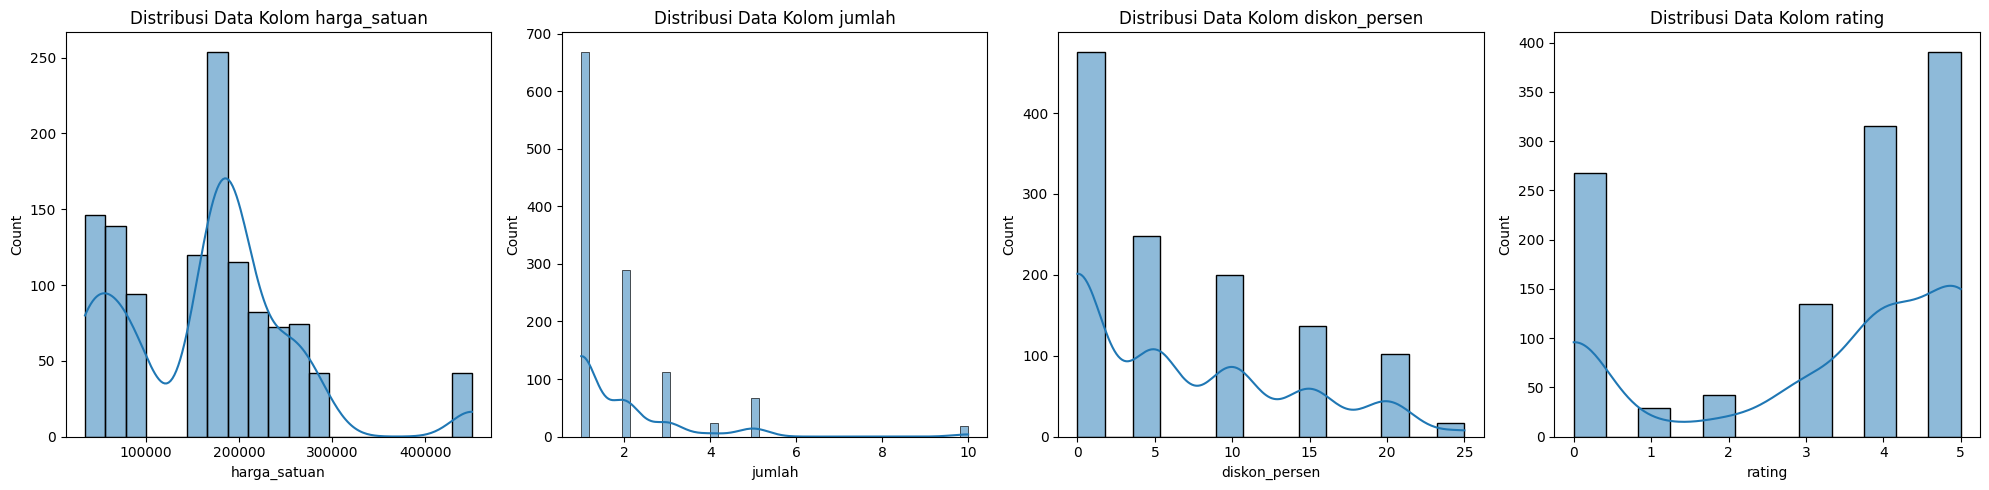

In [ ]:
# Cek distribusi data kolom numerik
num_cols = cleaned_df.select_dtypes(include="number").columns

# Histogram
fig, axs = plt.subplots(nrows=1, ncols=len(num_cols), figsize=(20, 5))

for i, col in enumerate(num_cols):
  sns.histplot(data=cleaned_df, x=col, ax=axs[i], kde=True)

  axs[i].set_title(f"Distribusi Data Kolom {col}")
  axs[i].set_xlabel(col)

plt.tight_layout()
plt.show()

### Proporsi Data Kolom Kategorikal

/tmp/ipykernel_1556/3881615079.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i].set_xticklabels(labels, rotation=30, ha="right")
/tmp/ipykernel_1556/3881615079.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i].set_xticklabels(labels, rotation=30, ha="right")
/tmp/ipykernel_1556/3881615079.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i].set_xticklabels(labels, rotation=30, ha="right")
/tmp/ipykernel_1556/3881615079.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i].set_xticklabels(labels, rotation=30, ha="right")
/tmp/ipykernel_1556/3881615079.py:17: UserWarning: set_ticklabels() should only be used with a fixed num

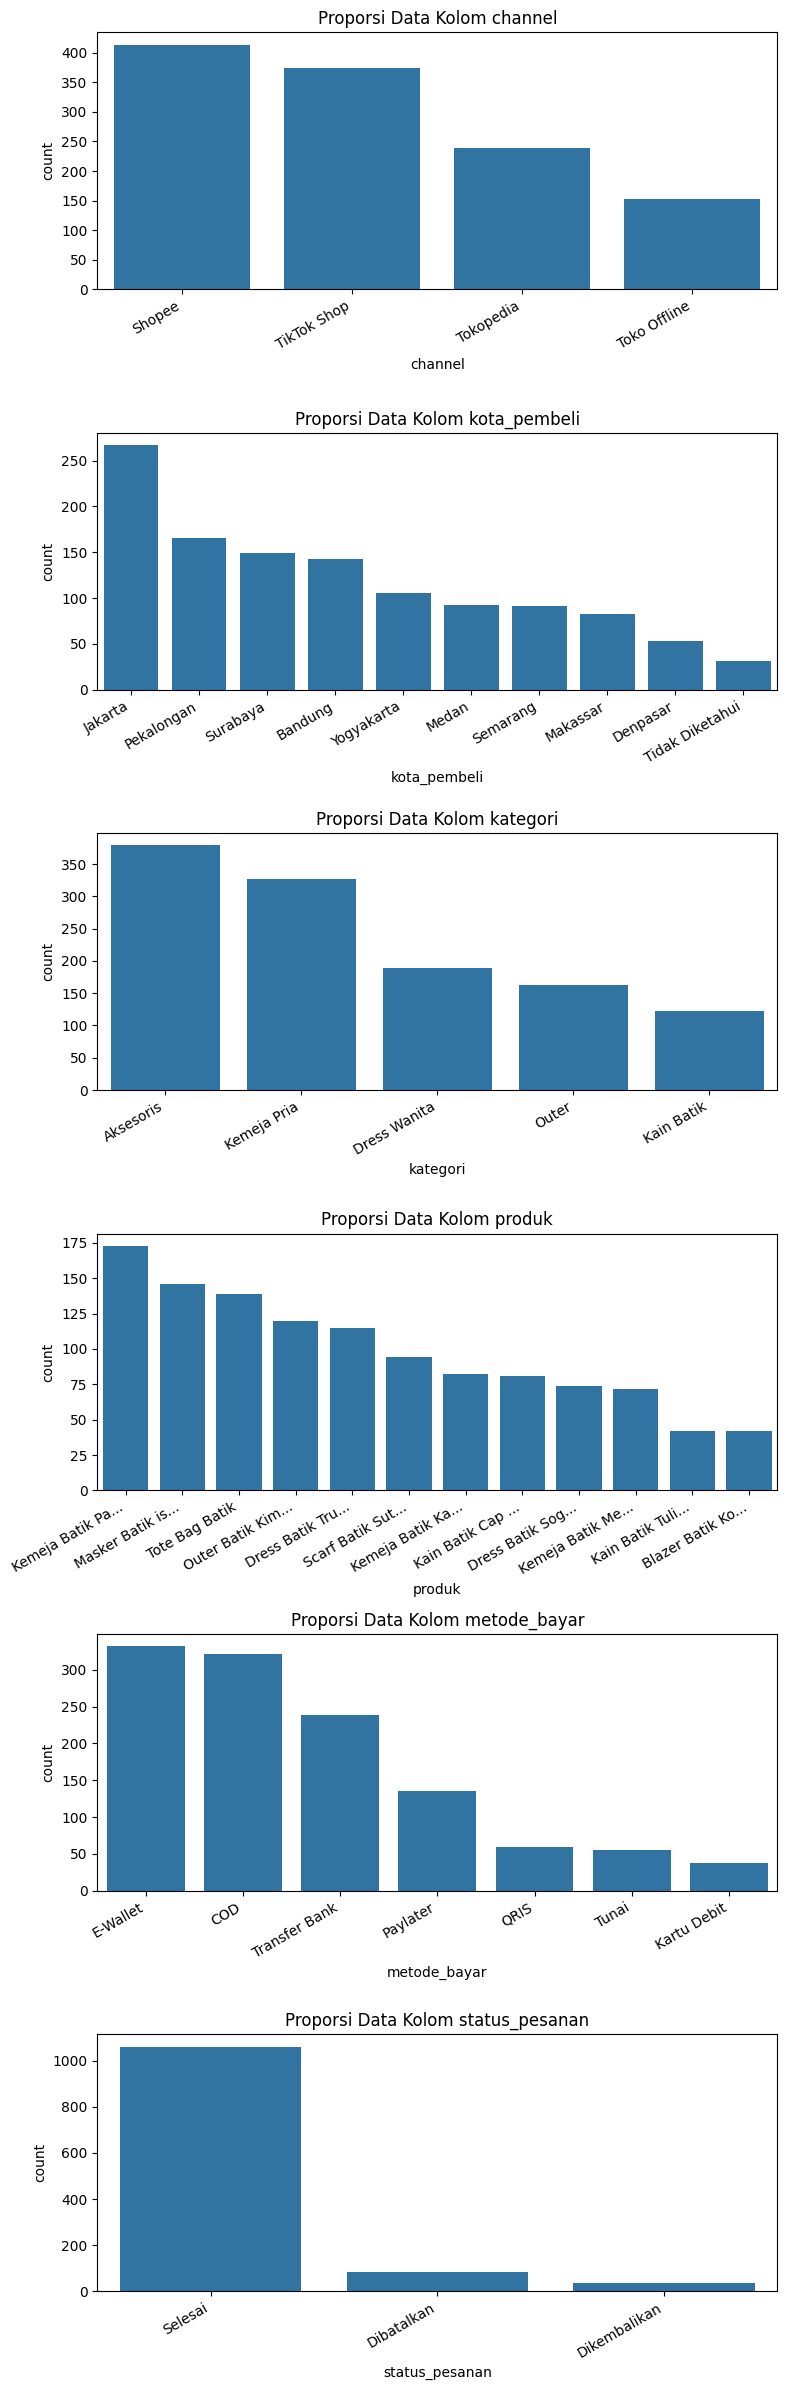

In [ ]:
# Cek proporsi data kolom kategorikal
cat_cols = cleaned_df.select_dtypes(include="object").drop(columns=["id_pesanan"], errors="ignore").columns

# Countplot
fig, axs = plt.subplots(nrows=len(cat_cols), ncols=1, figsize=(8, 4 * len(cat_cols)))

def truncate_label(text, max_len=15):
    text = str(text)
    return text if len(text) <= max_len else text[:max_len] + "..."

for i, col in enumerate(cat_cols):
    sns.countplot(data=cleaned_df, x=col, ax=axs[i], order=cleaned_df[col].value_counts().index)
    axs[i].set_title(f"Proporsi Data Kolom {col}")
    axs[i].set_xlabel(col)

    labels = [truncate_label(label.get_text(), max_len=15) for label in axs[i].get_xticklabels()]
    axs[i].set_xticklabels(labels, rotation=30, ha="right")

plt.tight_layout()
plt.show()

### Eksplorasi Lainnya [ Tambahkan Sesuai Kebutuhan ]  

## Feature Engineering

In [ ]:
def palet_biru(n):
    # Gradasi dari #265fa3 (biru tua) ke biru muda
    tua = np.array([0x26, 0x5f, 0xa3]) / 255
    muda = np.array([0xc2, 0xd9, 0xf0]) / 255
    return [tuple(tua + (muda - tua) * i / max(n - 1, 1)) for i in range(n)]

### Tambahkan Kolom `pendapatan_bersih`

_Ketentuan_:
* `pendapatan_bersih` = harga_satuan x jumlah x (1 - diskon_persen / 100)

* Pendpatan Riil, jika:
  - `status_pesanan` == "Selesai".
* Pendapatan Invalid (dianggap nol), jika:
  - `status_pesanan` == "Dibatalkan"
  - `status_pesanan` == "Dikembalikan"

In [ ]:
# Hitung nilai transaksi setelah diskon
nilai_transaksi = (
    cleaned_df["harga_satuan"]
    * cleaned_df["jumlah"]
    * (1 - cleaned_df["diskon_persen"] / 100)
)

In [ ]:
# Pendapatan hanya dihitung jika statusnya "Selesai"
# Status "Dibatalkan" dan "Dikembalikan" dianggap 0
cleaned_df["pendapatan_bersih"] = np.where(
    cleaned_df["status_pesanan"] == "Selesai",
    nilai_transaksi,
    0
)

### Tambahkan Kolom `bulan` dari `tanggal_pesanan`

Hint:
- `bulan` = `df["tanggal_pesanan"].dt.month`

In [ ]:
cleaned_df["bulan"] = cleaned_df["tanggal_pesanan"].dt.month

In [ ]:
# Cek hasil akhir
cleaned_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1180 entries, 0 to 1205
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   id_pesanan         1180 non-null   object        
 1   tanggal_pesanan    1180 non-null   datetime64[ns]
 2   channel            1180 non-null   object        
 3   kota_pembeli       1180 non-null   object        
 4   kategori           1180 non-null   object        
 5   produk             1180 non-null   object        
 6   harga_satuan       1180 non-null   int64         
 7   jumlah             1180 non-null   int64         
 8   diskon_persen      1180 non-null   int64         
 9   metode_bayar       1180 non-null   object        
 10  status_pesanan     1180 non-null   object        
 11  rating             1180 non-null   float64       
 12  pendapatan_bersih  1180 non-null   float64       
 13  bulan              1180 non-null   int32         
dtypes: datetime64

In [ ]:
cleaned_df.head(10)

,id_pesanan,tanggal_pesanan,channel,kota_pembeli,kategori,produk,harga_satuan,jumlah,diskon_persen,metode_bayar,status_pesanan,rating,pendapatan_bersih,bulan
0,BL-00001,2026-07-01,Shopee,Yogyakarta,Kemeja Pria,Kemeja Batik Parang Lengan Pendek,185000,1,5,Transfer Bank,Selesai,5.0,175750.0,7
1,BL-00002,2026-07-01,Tokopedia,Pekalongan,Aksesoris,Scarf Batik Sutra,95000,1,10,COD,Selesai,4.0,85500.0,7
2,BL-00003,2026-07-01,Toko Offline,Pekalongan,Kemeja Pria,Kemeja Batik Kawung Slim Fit,215000,1,10,QRIS,Selesai,5.0,193500.0,7
3,BL-00004,2026-07-01,Toko Offline,Semarang,Kemeja Pria,Kemeja Batik Mega Mendung Lengan Panjang,245000,3,0,QRIS,Selesai,4.0,735000.0,7
4,BL-00005,2026-07-01,Toko Offline,Jakarta,Outer,Outer Batik Kimono,159000,2,5,Kartu Debit,Selesai,4.0,302100.0,7
5,BL-00006,2026-07-01,TikTok Shop,Surabaya,Aksesoris,Masker Batik isi 3,35000,1,0,Paylater,Selesai,3.0,35000.0,7
6,BL-00007,2026-07-01,Shopee,Makassar,Aksesoris,Masker Batik isi 3,35000,1,0,Transfer Bank,Selesai,3.0,35000.0,7
7,BL-00008,2026-07-01,Tokopedia,Medan,Kemeja Pria,Kemeja Batik Parang Lengan Pendek,185000,1,0,COD,Selesai,5.0,185000.0,7
8,BL-00009,2026-07-01,Shopee,Denpasar,Kemeja Pria,Kemeja Batik Mega Mendung Lengan Panjang,245000,1,10,Transfer Bank,Dibatalkan,0.0,0.0,7
9,BL-00010,2026-07-01,TikTok Shop,Yogyakarta,Dress Wanita,Dress Batik Sogan Midi,265000,1,0,Transfer Bank,Selesai,5.0,265000.0,7


## ANALISIS

### P1: Channel dengan Pendapatan Bersih Terbesar

#### Pivot Table

In [ ]:
# Pendapatan bersih per channel urutan dari terbesar
pendapatan_channel = (
    cleaned_df.groupby("channel")["pendapatan_bersih"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

In [ ]:
# Tambahkan kolom kontribusi (%) untuk lihat seberapa dominan channel teratas
total = pendapatan_channel["pendapatan_bersih"].sum()
pendapatan_channel["kontribusi_persen"] = (
    pendapatan_channel["pendapatan_bersih"] / total * 100
).round(1)

print(pendapatan_channel)

        channel  pendapatan_bersih  kontribusi_persen
0        Shopee         95465350.0               34.5
1   TikTok Shop         82726700.0               29.9
2     Tokopedia         50022150.0               18.1
3  Toko Offline         48211700.0               17.4


In [ ]:
# Channel terbesar
top = pendapatan_channel.iloc[0]
print(f"\nChannel terbesar: {top['channel']}")
print(f"Pendapatan bersih: Rp {top['pendapatan_bersih']:,.0f} ({top['kontribusi_persen']}%)")


Channel terbesar: Shopee
Pendapatan bersih: Rp 95,465,350 (34.5%)


#### Visualisasi

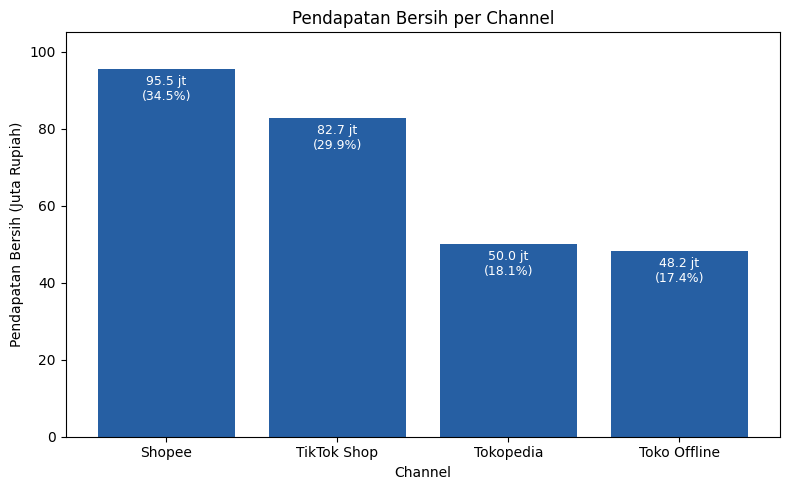

In [ ]:
plt.figure(figsize=(8, 5))
bars = plt.bar(
    pendapatan_channel["channel"],
    pendapatan_channel["pendapatan_bersih"] / 1_000_000,
    color="#265fa3"
)

for bar, persen in zip(bars, pendapatan_channel["kontribusi_persen"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() - 1.5,                      # sedikit di bawah ujung batang
        f"{bar.get_height():,.1f} jt\n({persen}%)",
        ha="center", va="top", color="white", fontsize=9
    )

plt.title("Pendapatan Bersih per Channel")
plt.xlabel("Channel")
plt.ylabel("Pendapatan Bersih (Juta Rupiah)")
plt.ylim(0, pendapatan_channel["pendapatan_bersih"].max() / 1_000_000 * 1.1)
plt.tight_layout()
plt.show()

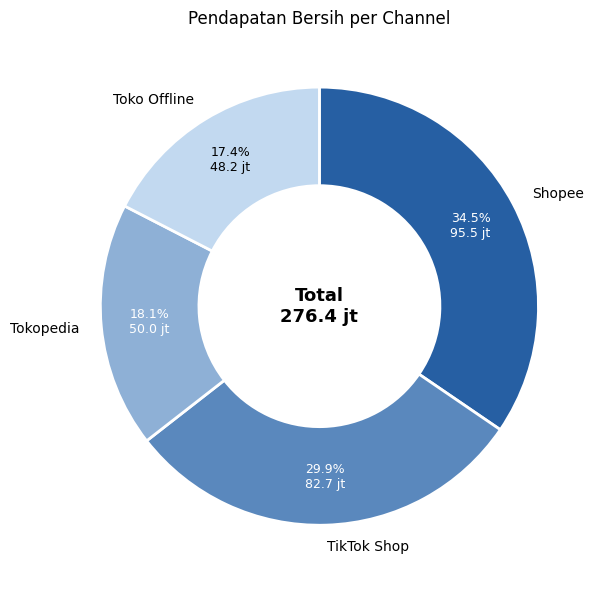

In [ ]:
data = pendapatan_channel.sort_values("pendapatan_bersih", ascending=False)
warna = palet_biru(len(data))
total_juta = data["pendapatan_bersih"].sum() / 1_000_000

fig, ax = plt.subplots(figsize=(8, 6))
wedges, texts, autotexts = ax.pie(
    data["pendapatan_bersih"] / 1_000_000,
    labels=data["channel"],
    colors=warna,
    startangle=90,
    counterclock=False,
    pctdistance=0.78,
    autopct=lambda p: f"{p:.1f}%\n{p * total_juta / 100:,.1f} jt",
    wedgeprops=dict(width=0.45, edgecolor="white", linewidth=2),
    textprops=dict(fontsize=10)
)

for i, at in enumerate(autotexts):
    at.set_color("white" if i < len(data) - 1 else "black")
    at.set_fontsize(9)

ax.text(0, 0, f"Total\n{total_juta:,.1f} jt", ha="center", va="center",
        fontsize=13, fontweight="bold")

ax.set_title("Pendapatan Bersih per Channel")
plt.tight_layout()
plt.show()

#### Temuan

1. Shopee (34,5%) dan TikTok Shop (29,9%) menyumbang 64,4% dari total pendapatan yaitu Rp 276 juta.
2. Tokopedia dan Toko Offline tertinggal jauh dan total pendapatan bersihnya hampir sama (hanya Rp 1,8 juta).
3. 82,6% pendapatan berasal dari online. Toko offline hanya 17,4%.


### P2-A: Kategori Terlaris (Paling Banyak Dipesan)

* Berdasarkan jumlah item terjual

#### Pivot Table

In [ ]:
df_selesai = cleaned_df[cleaned_df["status_pesanan"] == "Selesai"]

pivot_item = pd.pivot_table(
    df_selesai,
    index="kategori",
    values="jumlah",
    aggfunc="sum"
).rename(columns={"jumlah": "item_terjual"})

pivot_item = pivot_item.sort_values("item_terjual", ascending=False)
pivot_item["kontribusi_persen"] = (
    pivot_item["item_terjual"] / pivot_item["item_terjual"].sum() * 100
).round(1)
pivot_item["kumulatif_persen"] = pivot_item["kontribusi_persen"].cumsum().round(1)
pivot_item = pivot_item.reset_index()

print(pivot_item)

top_item = pivot_item.iloc[0]
print(f"\nKategori paling laris: {top_item['kategori']}")
print(f"Item terjual: {top_item['item_terjual']:,.0f} ({top_item['kontribusi_persen']}%)")

       kategori  item_terjual  kontribusi_persen  kumulatif_persen
0     Aksesoris           871               43.7              43.7
1   Kemeja Pria           450               22.6              66.3
2  Dress Wanita           268               13.5              79.8
3         Outer           227               11.4              91.2
4    Kain Batik           175                8.8             100.0

Kategori paling laris: Aksesoris
Item terjual: 871 (43.7%)


#### Visualisasi

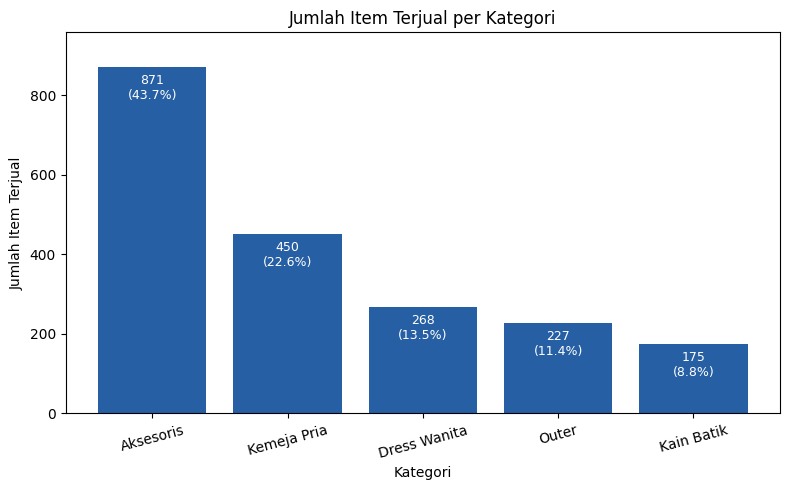

In [ ]:
plt.figure(figsize=(8, 5))
bars = plt.bar(
    pivot_item["kategori"],
    pivot_item["item_terjual"],
    color="#265fa3"
)

tinggi_max = pivot_item["item_terjual"].max()
batas = tinggi_max * 0.15   # batang dianggap pendek jika < 15% dari tertinggi

for bar, persen in zip(bars, pivot_item["kontribusi_persen"]):
    tinggi = bar.get_height()
    x = bar.get_x() + bar.get_width() / 2
    teks = f"{tinggi:,.0f}\n({persen}%)"

    if tinggi >= batas:
        # Di dalam batang, dekat ujung atas
        plt.text(x, tinggi - tinggi_max * 0.02, teks,
                 ha="center", va="top", color="white", fontsize=9)
    else:
        # Batang pendek: di luar batang, warna hitam
        plt.text(x, tinggi + tinggi_max * 0.01, teks,
                 ha="center", va="bottom", color="black", fontsize=9)

plt.title("Jumlah Item Terjual per Kategori")
plt.xlabel("Kategori")
plt.ylabel("Jumlah Item Terjual")
plt.ylim(0, tinggi_max * 1.1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

#### Temuan

1.   Aksesoris merupakan kategori paling laris (paling banyak dipesan) yaitu 871 item (43,7%) dari total 1.991 item
2.   Kemeja pria merupakan kategori kedua terbanyak dengan penjualan 450 item (22,6%), disusul oleh dress wanit sebanyak 268 item (13,5%), outer 227 item (11,4%), dan kain batik 175 item (8.8%).
1.   Kategori aksesoris banyak terjual karena harganya murah, sehingga pembeli mudha membeli dalam jumlah banyak.



### P2-B: Kategori dengan Pendapatan Tertinggi

#### Pivot Table

In [ ]:
pivot_pendapatan = pd.pivot_table(
    df_selesai,
    index="kategori",
    values=["pendapatan_bersih", "jumlah"],
    aggfunc="sum"
).rename(columns={"jumlah": "item_terjual"})

pivot_pendapatan = pivot_pendapatan.sort_values("pendapatan_bersih", ascending=False)
pivot_pendapatan["kontribusi_persen"] = (
    pivot_pendapatan["pendapatan_bersih"] / pivot_pendapatan["pendapatan_bersih"].sum() * 100
).round(1)
pivot_pendapatan["pendapatan_per_item"] = (
    pivot_pendapatan["pendapatan_bersih"] / pivot_pendapatan["item_terjual"]
).round(0)
pivot_pendapatan = pivot_pendapatan.reset_index()

print(pivot_pendapatan[["kategori", "pendapatan_bersih", "kontribusi_persen",
                        "item_terjual", "pendapatan_per_item"]])

top_pend = pivot_pendapatan.iloc[0]
print(f"\nKategori pendapatan terbesar: {top_pend['kategori']}")
print(f"Pendapatan bersih: Rp {top_pend['pendapatan_bersih']:,.0f} ({top_pend['kontribusi_persen']}%)")

# Perbandingan dengan 2A
print("\nApakah sama dengan kategori terlaris (2A)?",
      "Ya" if top_pend["kategori"] == top_item["kategori"] else "Tidak")

       kategori  pendapatan_bersih  kontribusi_persen  item_terjual  \
0   Kemeja Pria         85313000.0               30.9           450   
1  Dress Wanita         57146250.0               20.7           268   
2     Aksesoris         49207500.0               17.8           871   
3    Kain Batik         44663750.0               16.2           175   
4         Outer         40095400.0               14.5           227   

   pendapatan_per_item  
0             189584.0  
1             213232.0  
2              56495.0  
3             255221.0  
4             176632.0  

Kategori pendapatan terbesar: Kemeja Pria
Pendapatan bersih: Rp 85,313,000 (30.9%)

Apakah sama dengan kategori terlaris (2A)? Tidak


#### Visualisasi

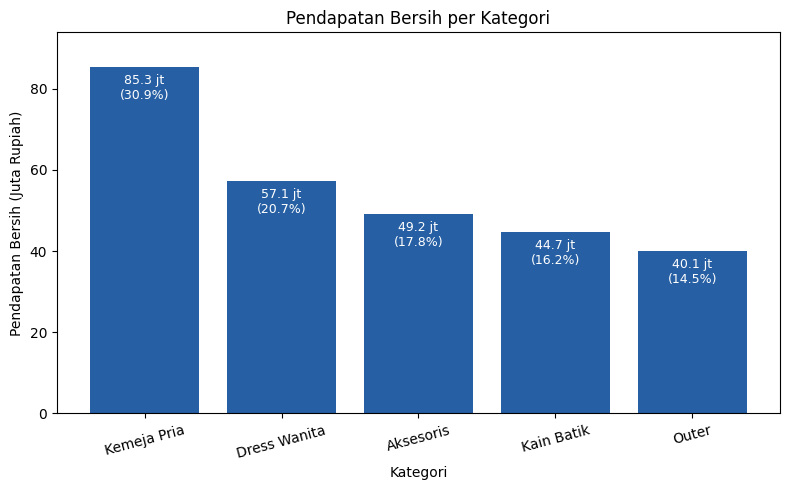

In [ ]:
plt.figure(figsize=(8, 5))
bars = plt.bar(
    pivot_pendapatan["kategori"],
    pivot_pendapatan["pendapatan_bersih"] / 1_000_000,
    color="#265fa3"
)

tinggi_max = pivot_pendapatan["pendapatan_bersih"].max() / 1_000_000
batas = tinggi_max * 0.15   # batang dianggap pendek jika < 15% dari tertinggi

for bar, persen in zip(bars, pivot_pendapatan["kontribusi_persen"]):
    tinggi = bar.get_height()
    x = bar.get_x() + bar.get_width() / 2
    teks = f"{tinggi:,.1f} jt\n({persen}%)"

    if tinggi >= batas:
        # Di dalam batang, dekat ujung atas
        plt.text(x, tinggi - tinggi_max * 0.02, teks,
                 ha="center", va="top", color="white", fontsize=9)
    else:
        # Batang pendek: di luar batang, warna hitam
        plt.text(x, tinggi + tinggi_max * 0.01, teks,
                 ha="center", va="bottom", color="black", fontsize=9)

plt.title("Pendapatan Bersih per Kategori")
plt.xlabel("Kategori")
plt.ylabel("Pendapatan Bersih (Juta Rupiah)")
plt.ylim(0, tinggi_max * 1.1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

#### Temuan



1.   Kemeja pria merupakan kategori pendapatan bersih terbesar, yaitu Rp85,3 juta (30,9%) dari total Rp276,4jt.
2.   Kategori aksesoris paling laris, tetapi pendapatannya hanya Rp49,2jt (17,8%) dan berada di peringkat 3, di bawah kemaja pria dan dress wanita.
1.   Penyebabnya adalah harga satuan. Satu item Kemeja Pria rata-rata menghasilkan sekitar Rp 190 ribu, hampir 3,4 kali lipat satu item Aksesoris (sekitar Rp 56 ribu). Volume besar dengan harga kecil tidak cukup untuk mengalahkan kategori berharga tinggi.
1.   Kain Batik adalah kategori yang paling jarang terjual (175 item), tetapi pendapatan per itemnya paling tinggi (sekitar Rp 255 ribu). Karena itu pendapatannya (Rp 44,7 juta) masih di atas Outer (Rp 40,1 juta).






### P2-C: Hubungan Jumlah Item Terjual vs Pendapatan

In [ ]:
# Gabungkan data item terjual dan pendapatan per kategori
df_hubungan = pivot_pendapatan[["kategori", "item_terjual", "pendapatan_bersih",
                                "pendapatan_per_item"]].copy()
df_hubungan["pendapatan_juta"] = df_hubungan["pendapatan_bersih"] / 1_000_000

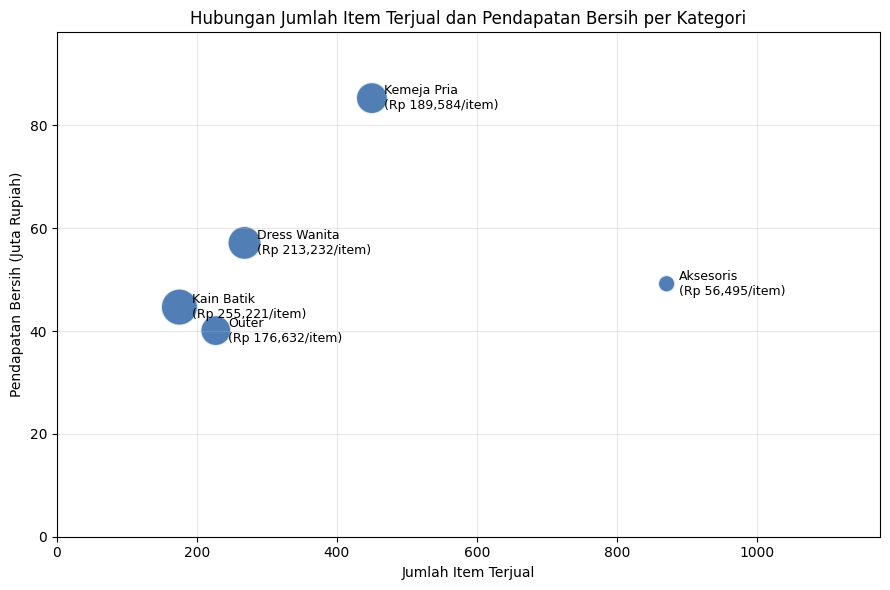

In [ ]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df_hubungan,
    x="item_terjual",
    y="pendapatan_juta",
    size="pendapatan_per_item",   # ukuran titik = rata-rata pendapatan per item
    sizes=(150, 700),
    color="#265fa3",
    alpha=0.8,
    legend=False
)

# Label nama kategori di samping titik
for _, row in df_hubungan.iterrows():
    plt.text(
        row["item_terjual"] + df_hubungan["item_terjual"].max() * 0.02,
        row["pendapatan_juta"],
        f"{row['kategori']}\n(Rp {row['pendapatan_per_item']:,.0f}/item)",
        va="center", fontsize=9
    )

plt.title("Hubungan Jumlah Item Terjual dan Pendapatan Bersih per Kategori")
plt.xlabel("Jumlah Item Terjual")
plt.ylabel("Pendapatan Bersih (Juta Rupiah)")
plt.xlim(0, df_hubungan["item_terjual"].max() * 1.35)   # ruang untuk label
plt.ylim(0, df_hubungan["pendapatan_juta"].max() * 1.15)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

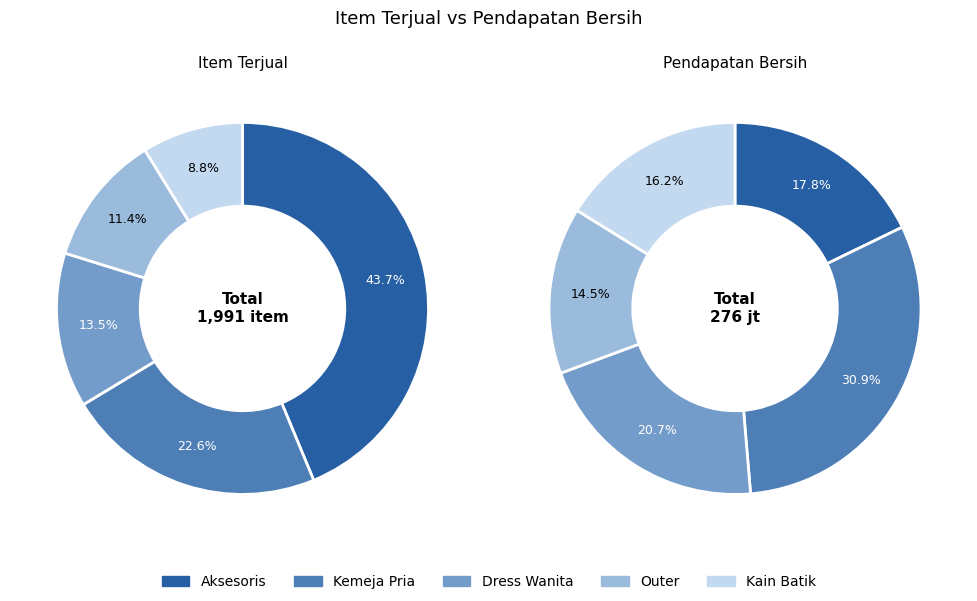

In [ ]:
# Samakan urutan kategori di kedua donut
urutan = pivot_item["kategori"].tolist()
item = pivot_item.set_index("kategori").loc[urutan, "item_terjual"]
pend = pivot_pendapatan.set_index("kategori").loc[urutan, "pendapatan_bersih"] / 1_000_000

warna = palet_biru(len(urutan))
peta_warna = dict(zip(urutan, warna))

def gambar_donut(ax, nilai, judul, tengah, satuan):
    total = nilai.sum()
    wedges, texts, autotexts = ax.pie(
        nilai,
        colors=[peta_warna[k] for k in nilai.index],
        startangle=90,
        counterclock=False,
        pctdistance=0.78,
        autopct=lambda p: f"{p:.1f}%",
        wedgeprops=dict(width=0.45, edgecolor="white", linewidth=2),
    )
    for i, at in enumerate(autotexts):
        at.set_color("white" if i < len(nilai) - 2 else "black")
        at.set_fontsize(9)
    ax.text(0, 0, f"{tengah}\n{total:,.0f} {satuan}", ha="center", va="center",
            fontsize=11, fontweight="bold")
    ax.set_title(judul, fontsize=11)

fig, axes = plt.subplots(1, 2, figsize=(10, 6))
fig.subplots_adjust(wspace=0.05)
gambar_donut(axes[0], item, "Item Terjual", "Total", "item")
gambar_donut(axes[1], pend, "Pendapatan Bersih", "Total", "jt")

# Satu legenda bersama
fig.legend(
    handles=[plt.Rectangle((0, 0), 1, 1, color=peta_warna[k]) for k in urutan],
    labels=urutan, loc="lower center", ncol=len(urutan), frameon=False
)
fig.suptitle("Item Terjual vs Pendapatan Bersih",
             fontsize=13)
plt.tight_layout(rect=[0, 0.07, 1, 0.95])
plt.show()

### P3-A: Trend Pendapatan Bulanan

#### Pivot Table

In [ ]:
# Menghitung total pendapatan bersih per bulan
tren_bulan = cleaned_df.groupby('bulan')['pendapatan_bersih'].sum().reset_index()

# Ubah angka bulan jadi nama bulan
bulan_map = {7: 'Juli', 8: 'Agustus', 9: 'September'}
tren_bulan['nama_bulan'] = tren_bulan['bulan'].map(bulan_map)

# Hitung kontribusi persen
total_pendapatan = tren_bulan['pendapatan_bersih'].sum()
tren_bulan['kontribusi_persen'] = (tren_bulan['pendapatan_bersih'] / total_pendapatan * 100).round(1)

tabel_tampil = tren_bulan[['nama_bulan', 'pendapatan_bersih', 'kontribusi_persen']].copy()

# Format teks Rp dan %
tabel_tampil['pendapatan_bersih'] = tabel_tampil['pendapatan_bersih'].apply(lambda x: f"Rp {x:,.0f}")
tabel_tampil['kontribusi_persen'] = tabel_tampil['kontribusi_persen'].apply(lambda x: f"{x}%")

print(tabel_tampil)

  nama_bulan pendapatan_bersih kontribusi_persen
0       Juli     Rp 91,570,450             33.1%
1    Agustus     Rp 99,661,750             36.1%
2  September     Rp 85,193,700             30.8%


#### Visualisasi

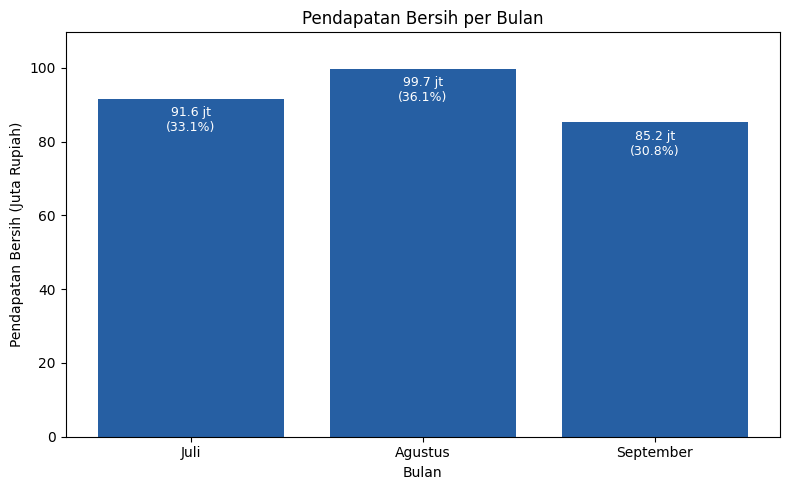

In [ ]:
plt.figure(figsize=(8, 5))
bars = plt.bar(
    tren_bulan["nama_bulan"],
    tren_bulan["pendapatan_bersih"] / 1_000_000,
    color="#265fa3"
)

tinggi_max = tren_bulan["pendapatan_bersih"].max() / 1_000_000

for bar, persen in zip(bars, tren_bulan["kontribusi_persen"]):
    tinggi = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        tinggi - tinggi_max * 0.02,
        f"{tinggi:,.1f} jt\n({persen}%)",
        ha="center", va="top", color="white", fontsize=9
    )

plt.title("Pendapatan Bersih per Bulan")
plt.xlabel("Bulan")
plt.ylabel("Pendapatan Bersih (Juta Rupiah)")
plt.ylim(0, tinggi_max * 1.1)
plt.tight_layout()
plt.show()

#### Temuan

*  Pendapatan bersih tertinggi selama periode Juli hingga September 2026 terjadi pada bulan Agustus dengan total pencapaian 99,7 juta rupiah, menyumbang 36,1% dari keseluruhan pendapatan pada kuartal tersebut.
*   Performa terendah tercatat pada bulan September, yang mengalami penurunan dari bulan sebelumnya menjadi 85,2 juta rupiah atau sebesar 30,8%.
*   Bulan Juli mengawali periode dengan kontribusi yang cukup stabil di pertengahan, yakni sebesar 91,6 juta rupiah (33,1%).






### P3-B: Trend Pendapatan Harian

#### Pivot Table

In [ ]:
# Menghitung total pendapatan bersih per hari
tren_harian = cleaned_df.groupby('tanggal_pesanan')['pendapatan_bersih'].sum().reset_index()

# Tentukan tanggal kembar
tanggal_kembar = ['2026-07-07', '2026-08-08', '2026-09-09']

# Buat penanda (flag) untuk tanggal kembar
tren_harian['is_tanggal_kembar'] = tren_harian['tanggal_pesanan'].astype(str).isin(tanggal_kembar)

# Tampilkan Pivot Table rata-rata perbandingan
perbandingan = tren_harian.groupby('is_tanggal_kembar')['pendapatan_bersih'].mean().reset_index()
perbandingan['Keterangan'] = ['Hari Biasa', 'Tanggal Kembar']
perbandingan['pendapatan_bersih'] = perbandingan['pendapatan_bersih'].apply(lambda x: f"Rp {x:,.0f}") # Mengubah jadi Rp. juta

print("Rata-rata Pendapatan Harian:")
print(perbandingan[['Keterangan', 'pendapatan_bersih']])

Rata-rata Pendapatan Harian:
       Keterangan pendapatan_bersih
0      Hari Biasa      Rp 2,891,878
1  Tanggal Kembar      Rp 6,349,583


#### Visualisasi

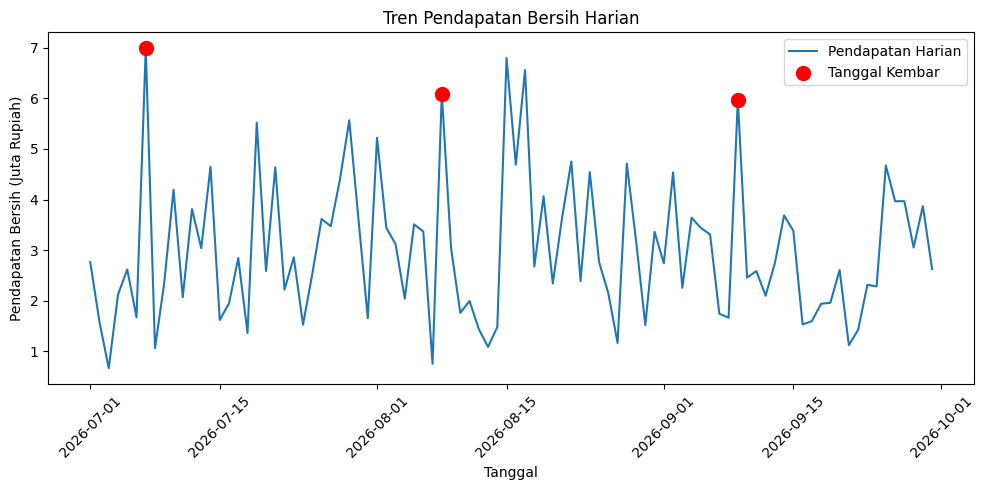

In [ ]:
plt.figure(figsize=(10, 5))

# 1. Membuat garis tren harian (dibagi 1 juta agar sumbu Y rapi)
plt.plot(
    tren_harian["tanggal_pesanan"],
    tren_harian["pendapatan_bersih"] / 1_000_000,
    color="#1f77b4",
    label="Pendapatan Harian"
)

# 2. Menambahkan titik merah khusus untuk tanggal kembar
data_kembar = tren_harian[tren_harian['is_tanggal_kembar']]
plt.scatter(
    data_kembar["tanggal_pesanan"],
    data_kembar["pendapatan_bersih"] / 1_000_000,
    color="red",
    s=100, # Ukuran titik
    zorder=5, # Memastikan titik ada di atas garis
    label="Tanggal Kembar"
)

# 3. Pengaturan judul dan label
plt.title("Tren Pendapatan Bersih Harian")
plt.xlabel("Tanggal")
plt.ylabel("Pendapatan Bersih (Juta Rupiah)")
plt.xticks(rotation=45) # Memiringkan teks tanggal agar tidak bertabrakan
plt.legend()
plt.tight_layout()

# Tampilkan grafik
plt.show()

#### Temuan

*   Pendapatan bersih pada hari-hari biasa berfluktuasi secara ekstrem dan mayoritas bergerak di kisaran 1 hingga 5 juta rupiah per hari.
*   Kampanye tanggal kembar secara konsisten berhasil menciptakan lonjakan penjualan (ditandai dengan titik merah), dengan capaian sekitar 6 juta rupiah pada 8 Agustus dan 9 September, serta menembus titik tertinggi 7 juta rupiah pada 7 Juli.
*   Terdapat satu lonjakan anomali di luar momen tanggal kembar pada pertengahan bulan Agustus, di mana pendapatan melesat sangat tajam mendekati angka 7 juta rupiah (hampir menyamai rekor penjualan 7 Juli). Hal ini bisa menjadi indikasi adanya promosi dadakan, pesanan dalam jumlah besar, atau tren produk tertentu yang viral pada hari tersebut.





### P4: Persentase Metode Pembayaran yang Paling Sering Batal/Dibatalkan

* Dihitung dalam persen dari total pesanan metode
tersebut.

#### Pivot Table

In [ ]:
# Total pesanan dan jumlah batal per metode bayar
total_pesanan = cleaned_df.groupby("metode_bayar")["id_pesanan"].count()

total_batal = (
    cleaned_df[cleaned_df["status_pesanan"] == "Dibatalkan"]
    .groupby("metode_bayar")["id_pesanan"]
    .count()
)

# Gabung dan hitung persentase batal
batal_metode = pd.DataFrame({
    "total_pesanan": total_pesanan,
    "total_batal": total_batal
}).fillna(0)

batal_metode["total_batal"] = batal_metode["total_batal"].astype(int)
batal_metode["persen_batal"] = (
    batal_metode["total_batal"] / batal_metode["total_pesanan"] * 100
).round(1)

batal_metode = batal_metode.sort_values("persen_batal", ascending=False).reset_index()
print(batal_metode)

    metode_bayar  total_pesanan  total_batal  persen_batal
0            COD            322           47          14.6
1       Paylater            136           12           8.8
2       E-Wallet            332           16           4.8
3  Transfer Bank            238            9           3.8
4    Kartu Debit             38            0           0.0
5           QRIS             59            0           0.0
6          Tunai             55            0           0.0


In [ ]:
# Metode dengan pembatalan tertinggi
top = batal_metode.iloc[0]
print(f"\nMetode paling sering dibatalkan: {top['metode_bayar']}")
print(f"Tingkat pembatalan: {top['persen_batal']}% "
      f"({top['total_batal']} dari {top['total_pesanan']} pesanan)")


Metode paling sering dibatalkan: COD
Tingkat pembatalan: 14.6% (47 dari 322 pesanan)


#### Visualisasi

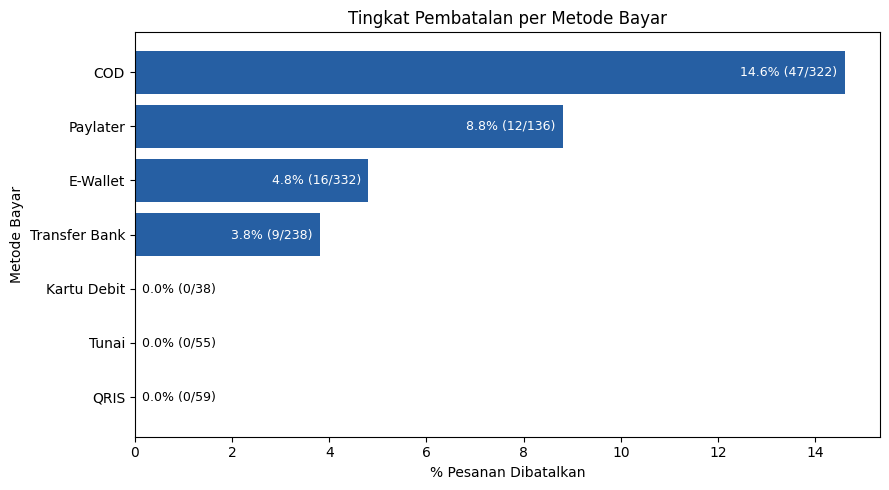

In [ ]:
import matplotlib.pyplot as plt

batal_sorted = batal_metode.sort_values("persen_batal", ascending=True)

plt.figure(figsize=(9, 5))
bars = plt.barh(batal_sorted["metode_bayar"], batal_sorted["persen_batal"], color="#265fa3")

batas = batal_sorted["persen_batal"].max() * 0.25  # batang dianggap pendek jika < 25% dari terpanjang

for bar, persen, batal, total in zip(
    bars,
    batal_sorted["persen_batal"],
    batal_sorted["total_batal"],
    batal_sorted["total_pesanan"],
):
    y = bar.get_y() + bar.get_height() / 2
    teks = f"{persen:.1f}% ({batal}/{total})"

    if persen >= batas:
        # Di dalam batang, warna putih
        plt.text(persen - 0.15, y, teks, ha="right", va="center", color="white", fontsize=9)
    else:
        # Nilai 0% atau batang pendek: di luar batang, warna hitam
        plt.text(persen + 0.15, y, teks, ha="left", va="center", color="black", fontsize=9)

plt.title("Tingkat Pembatalan per Metode Bayar")
plt.xlabel("% Pesanan Dibatalkan")
plt.ylabel("Metode Bayar")
plt.tight_layout()
plt.show()

#### Temuan

*   COD paling sering dibatalkan: 14,6% (47 dari 322 pesanan). Itu hampir 1 dari 7 pesanan COD.
*   Paylater di urutan kedua: 8,8% (12 dari 136 pesanan).
*   E-Wallet 4,8% dan Transfer Bank 3,8% tergolong rendah.
*   Kartu Debit, Tunai, dan QRIS tidak ada yang batal (0%), tetapi jumlah pesanannya kecil (38, 55, dan 59 pesanan).





### P5: Kota dengan Pembelian Terbanyak

#### Pivot Table

In [ ]:
# Group by Jumlah Pembelian per Kota
top_kota_by_transaction = (
    cleaned_df.groupby("kota_pembeli")["id_pesanan"]
    .nunique()
    .sort_values(ascending=True)
    .reset_index()
)

top_kota_by_transaction.tail(5)

,kota_pembeli,id_pesanan
5,Yogyakarta,106
6,Bandung,143
7,Surabaya,149
8,Pekalongan,165
9,Jakarta,267


#### Visualisasi

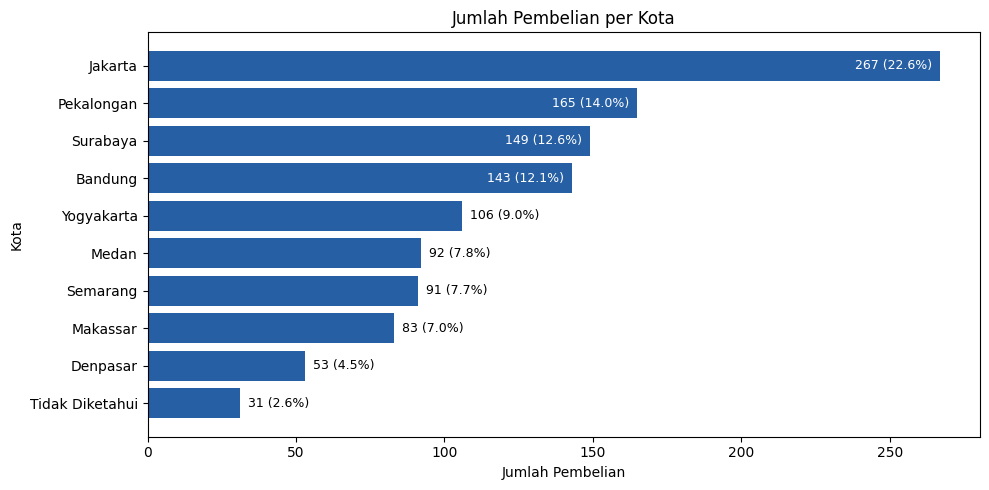

In [ ]:
# Horizontal Bar Chart Top Kota by Customer
plt.figure(figsize=(10, 5))
bars = plt.barh(
    top_kota_by_transaction["kota_pembeli"],
    top_kota_by_transaction["id_pesanan"],
    color="#265fa3"
)

total_pesanan = top_kota_by_transaction["id_pesanan"].sum()
max_pesanan = max(top_kota_by_transaction["id_pesanan"])

for bar, count in zip(bars, top_kota_by_transaction["id_pesanan"]):
    persentase = (count / total_pesanan) * 100

    if count > 0.5 * max_pesanan:
        plt.text(
            bar.get_width() - (max_pesanan * 0.01),
            bar.get_y() + bar.get_height() / 2,
            f"{count:,} ({persentase:.1f}%)",
            va="center", ha="right", fontsize=9, color="white", fontweight="roman"
        )
    else:
        plt.text(
            bar.get_width() + (max_pesanan * 0.01),
            bar.get_y() + bar.get_height() / 2,
            f"{count:,} ({persentase:.1f}%)",
            va="center", ha="left", fontsize=9, color="black", fontweight="roman"
        )

plt.title("Jumlah Pembelian per Kota")
plt.xlabel("Jumlah Pembelian")
plt.ylabel("Kota")
plt.tight_layout()
plt.show()

#### Temuan

- Pembelian selama Q3 didominasi oleh transaksi pembeli yang berasal dari Kota Jakarta (22,6%).
- Top 5 Kota dengan jumlah pembelian terbanyak selama Q3 meliputi:
  1. Jakarta (22,6%)
  2. Pekalongan (14%)
  3. Surabaya (12,6%)
  4. Bandung (12,1%)
  5. Yogyakarta (9%)


### P6: Rata-rata Rating per Kategori

#### Pivot Table

In [ ]:
# Cek rating 0
print(cleaned_df[cleaned_df['rating'] == 0].value_counts(subset="kategori"))

kategori
Kemeja Pria     88
Aksesoris       85
Outer           40
Dress Wanita    30
Kain Batik      25
Name: count, dtype: int64


In [ ]:
# Sisihkan yang rating = 0
rate_df = cleaned_df[cleaned_df['rating'] != 0]

# Hitung rata-rata rating per kategori
rate_per_category = (
    rate_df.groupby("kategori")["rating"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

rate_per_category

,kategori,rating
0,Kain Batik,4.214286
1,Aksesoris,4.132653
2,Outer,4.090164
3,Kemeja Pria,4.037657
4,Dress Wanita,4.031447


#### Visualisasi

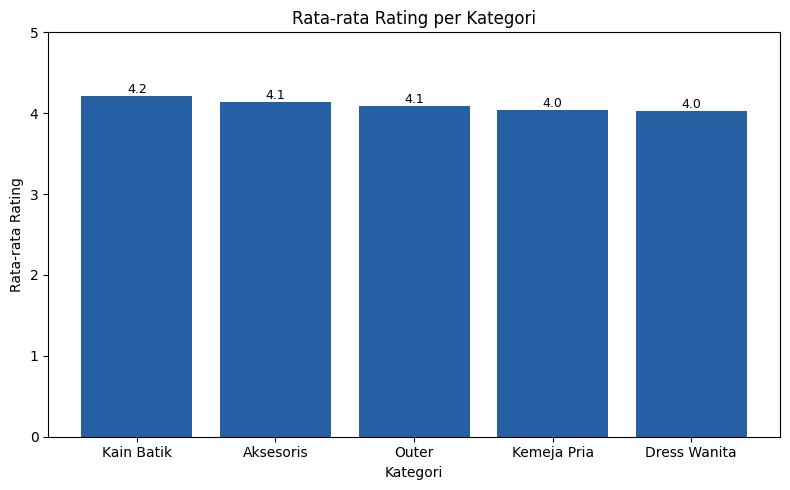

In [ ]:
# Vertikal bar chart rate per category
plt.figure(figsize=(8, 5))
bars = plt.bar(
    rate_per_category["kategori"],
    rate_per_category["rating"],
    color="#265fa3"
)

for bar, rating in zip(bars, rate_per_category["rating"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{rating:.1f}",
        ha="center", va="bottom", fontsize=9, fontweight="roman"
    )

plt.title("Rata-rata Rating per Kategori")
plt.xlabel("Kategori")
plt.ylabel("Rata-rata Rating")
plt.ylim(0, 5)
plt.tight_layout()
plt.show()

#### Temuan

- Rating nol diasumsikan bahwa customer belum memberikan rating atau ulasan terhadap produk yang dibeli.
- Rata-rata rating setiap kategori cenderung seimbang dengan rentang berkisar antara 4,2 - 4.
- Hal ini mengindikasikan bahwa mayoritas pembeli merasa cukup puas terhadap kualias produk dari setiap kategori yang dijual selama Q3. Meskipun begitu, masih ada ruang untuk melakukan peningkatan kualitas produk maupun layanan.

## INSIGHT UTAMA

### INSIGHT 1

**Dari P1:**

Bisnis sangat bergantung pada channel online, dimana tiktok shop menjadi channel paling kuat, hampir menyaingi Shopee (selisih hanya 12,8 juta) dan jauh diatas Tokopedia.
Artinya penjualan batik cocok dengan model penjualan berbasis konten dan live.
Di sisi lain, ketergantungan pada dua channel membuat bisnis rentan jika ada perubahan kebijakan atau biaya.

### INSIGHT 2

**Dari P2:**

Kategori terlaris belum tentu menghasilkan keuntungan terbesar pada bisnis. Kategori aksesoris memang memiliki penjualan terbanyak, namun dari kategori ini hanya menyumbang 17,8% terhadap pendapatan bersih sehingga hanya berada pada peringkat ketiga. Sebaliknya, kategori Kemeja Pria berhasil menghasilkan pendapatan terbesar dengan persentase 30,9%. Hal ini karena keuntungan rata-rata aksesoris hanya Rp56 ribu, sedangkan kemeja pria mencapai Rp190 ribu. Hal yang sama juga terjadi pada kategoi Dress Wanita dan Kain Batik, dimana keduanya memiliki porsi 20,7% dan 16,2%, yang lebih besar dari porsi penjualannya.

### INSIGHT 3

Pembatalan paling banyak terjadi pada metode di mana pembeli belum membayar saat memesan. COD baru bayar saat barang tiba, dan Paylater yang bayarnya belakangan. Pembeli lebih mudah berubah pikiran atau tidak ada di rumah saat kurir datang.

## REKOMENDASI

### ACTION 1

**Dari P1:**
1. Fokuskan anggaran promosi Q4 (10.10, 11.11, 12.12) ke Shopee dan TikTok Shop karena pangsanya paling besar.
2. Dorong TikTok Shop sebagai peluang pertumbuhan, bisa melalui live selling dan kreator.
3. Evaluasi tokopedia apakah cukup dipertahankan dengan usaha minimal. Toko offline dijadikan etalase brand untuk wisatawan dan pelanggan lokal.

### ACTION 2

**Dari P2:**
  
  Untuk Q4, stok Kemeja Pria dan Dress Wanita perlu disiapkan paling awal dan dengan cadangan yang cukup sebelum kampanye 10.10, 11.11, dan 12.12, karena kehabisan stok di dua kategori ini paling besar dampaknya terhadap omzet. Aksesoris sebaiknya diposisikan sebagai produk pendamping, misalnya lewat paket bundling atau hadiah pembelian di atas nominal tertentu, untuk menaikkan nilai keranjang belanja, bukan sebagai target omzet utama. Kain Batik cocok dijual sebagai produk premium musiman dengan stok terbatas atau sistem pre-order, sedangkan Outer perlu dievaluasi karena kontribusinya paling kecil (14,5%).

### ACTION 3

Kurangi pembatalan COD dengan konfirmasi pesanan lewat chat sebelum dikirim.
Arahkan pembeli ke pembayaran langsung (QRIS atau E-Wallet). Beri insentif kecil, misalnya potongan ongkir atau voucher, bagi yang bayar di awal.
Waspadai Q4. Saat 10.10, 11.11, dan 12.12 pesanan melonjak, sehingga resiko pembatalan COD ikut membengkak.